# RetailPulse — Step 2: Feature Engineering

**Goal of this step:** turn the raw sales lines into model-ready tables, so later steps only read prepared data.

| Output (in `data/processed/`) | One row per | Used by |
|---|---|---|
| `sales_clean.parquet` | sales line (duplicates removed) | every later step |
| `customer_features.csv` | customer | Step 3 segmentation, Step 4 churn |
| `daily_sales_features.csv` | day | Step 5 forecasting |
| `weekly_sales.csv` | week | Step 5 forecasting (reported accuracy) |
| `sku_weekly.csv` | top-20 SKU × week | Step 5 product forecasts, Step 6 inventory |
| `inventory_features.csv` | store × SKU | Step 6 inventory optimization |

The feature logic lives in `src/features.py` (and cleaning in `src/cleaning.py`) so that the notebooks, tests and dashboard all compute features the same way.
Choices below follow the Step 1 EDA findings (`01_data_analysis/eda.ipynb`, sections 11–12).

## 0. Setup

In [1]:
import sys, time
from pathlib import Path
import numpy as np, pandas as pd, duckdb
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display

ROOT = Path('..')
sys.path.append(str(ROOT))
from src.cleaning import build_clean_sales, connect
from src.features import (customer_features, daily_sales, add_time_features,
                          weekly_sales, sku_weekly, inventory_features)

DATA = ROOT / 'retail_clean_dataset'          # main dataset (same as Step 1)
PROC = ROOT / 'data' / 'processed'; PROC.mkdir(parents=True, exist_ok=True)
FIG  = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)

pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.figsize': (11, 4.5), 'figure.dpi': 110, 'axes.titleweight': 'bold'})
def save(name): plt.savefig(FIG / f'{name}.png', bbox_inches='tight')

## 1. Clean sales table
Step 1 showed the data is consistent (no broken keys, prices and `total_value` all check out), so cleaning is light:
remove exact duplicate lines, and keep a `quantity > 0` guard. The result is saved once as parquet and every later step reads it.

In [2]:
csv = DATA / 'sales_transactions.csv'
source = csv if csv.exists() else ROOT / '01_data_analysis' / 'cache' / 'sales_main.parquet'
t = time.time()
log = build_clean_sales(source, PROC / 'sales_clean.parquet', duckdb.connect())
print(f'built in {time.time() - t:.0f}s from {source.name}')

pd.DataFrame([
    {'Step': 'Raw sales lines', 'Rows removed': '-', 'Rows left': f"{log['raw_rows']:,}", 'Why': ''},
    {'Step': 'Exact duplicate lines / quantity <= 0', 'Rows removed': f"{log['removed_rows']:,}",
     'Rows left': f"{log['clean_rows']:,}", 'Why': 'Same line recorded twice would double-count demand'},
])

built in 6s from sales_transactions.csv


,Step,Rows removed,Rows left,Why
0,Raw sales lines,-,"9,972,038",
1,Exact duplicate lines / quantity <= 0,"13,019","9,959,019",Same line recorded twice would double-count de...


In [3]:
con = connect(DATA, PROC / 'sales_clean.parquet')
first, last = con.sql('SELECT MIN(date), MAX(date) FROM sales').fetchone()
SNAPSHOT = pd.Timestamp(last) + pd.Timedelta(days=1)    # "today" = the day after the last sale
print('sales from', first, 'to', last, '| snapshot date:', SNAPSHOT.date())

sales from 2022-01-01 to 2025-12-31 | snapshot date: 2026-01-01


## 2. Customer features (one row per customer)
`customer_features(con, snapshot)` only uses sales **before** the snapshot date. Today we run it with the snapshot = day after the last sale.
In Step 4 the same function is run at an earlier cutoff, and the churn label comes from what happens *after* the cutoff — that is what keeps the churn model free of leakage.

Tenure is measured from the **first purchase**, not `registration_date`, because the EDA found 37% of customers bought before they registered.

In [4]:
t = time.time()
cust = customer_features(con, SNAPSHOT)
print(f'{cust.shape[0]:,} customers x {cust.shape[1]} features  ({time.time() - t:.0f}s)')
cust.head()

10,000 customers x 48 features  (4s)


,recency_days,tenure_days,frequency,monetary,spend_30,spend_90,spend_prev_90,spend_180,spend_365,visits_30,visits_90,visits_prev_90,share_in_store,share_online,share_mobile_app,max_gap_days,gap_std_days,n_lines,units,unique_skus,...,cat_health_wellness,cat_home_kitchen,cat_home_care,cat_personal_care,cat_snacks_confectionery,cat_stationery_office,age,gender,city,loyalty_segment,preferred_channel,aov,items_per_basket,units_per_basket,avg_days_between,overdue_ratio,spend_trend_90,visits_trend_90,preferred_channel_share,days_since_registration
customer_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
CUST00001,3,1456,461,"945,708.54","19,693.65","77,135.85","68,243.99","145,379.84","241,201.56",13,35,37,0.16,0.80,0.04,17,3.07,880,"1,630.00",646,...,0.07,0.14,0.03,0.15,0.01,0.03,52,Female,Sukkur,Silver,Online,"2,051.43",1.91,3.54,3.16,0.95,0.13,-0.05,0.80,1826
CUST00002,2,1453,440,"969,764.01","40,569.77","105,770.45","33,976.45","139,746.90","282,980.50",18,43,21,0.17,0.08,0.75,27,3.67,880,"1,678.00",655,...,0.07,0.16,0.04,0.15,0.01,0.02,41,Female,Karachi,Silver,Mobile App,"2,204.01",2.00,3.81,3.31,0.61,2.11,1.05,0.75,1693
CUST00003,2,1449,323,"649,917.08","7,780.81","30,373.87","72,607.68","102,981.55","180,980.49",5,18,30,0.87,0.06,0.07,23,3.84,619,"1,164.00",488,...,0.07,0.16,0.05,0.12,0.01,0.03,48,Female,Bahawalpur,Bronze,In-Store,"2,012.13",1.92,3.60,4.49,0.45,-0.58,-0.40,0.87,1166
CUST00004,1,1455,475,"1,033,529.62","20,438.24","79,588.10","64,088.88","143,676.98","275,637.04",7,24,38,0.87,0.08,0.05,19,3.22,906,"1,719.00",661,...,0.07,0.16,0.04,0.14,0.01,0.03,45,Male,Karachi,Silver,In-Store,"2,175.85",1.91,3.62,3.07,0.33,0.24,-0.37,0.87,3823
CUST00005,3,1458,294,"600,792.95","21,427.59","65,080.03","26,567.40","91,647.43","170,119.13",12,32,15,0.85,0.10,0.05,37,4.90,568,"1,074.00",448,...,0.09,0.16,0.04,0.18,0.01,0.03,39,Female,Faisalabad,Bronze,In-Store,"2,043.51",1.93,3.65,4.97,0.60,1.45,1.13,0.85,730


In [5]:
groups = {
    'RFM':              ['recency_days', 'frequency', 'monetary', 'tenure_days'],
    'Basket':           ['aov', 'items_per_basket', 'units_per_basket', 'n_lines', 'units', 'unique_skus'],
    'Visit rhythm':     ['avg_days_between', 'max_gap_days', 'gap_std_days', 'overdue_ratio'],
    'Recent activity':  ['spend_30', 'spend_90', 'spend_prev_90', 'spend_180', 'spend_365',
                         'visits_30', 'visits_90', 'visits_prev_90', 'spend_trend_90', 'visits_trend_90'],
    'Promo use':        ['promo_line_share', 'discount_share'],
    'Channel':          ['share_in_store', 'share_online', 'share_mobile_app', 'preferred_channel_share'],
    'Category mix':     [c for c in cust.columns if c.startswith('cat_')],
    'Demographics':     ['age', 'gender', 'city', 'loyalty_segment', 'preferred_channel', 'days_since_registration'],
}
assert sorted(c for cols in groups.values() for c in cols) == sorted(cust.columns), 'every feature belongs to one group'
pd.DataFrame([{'Group': g, 'Count': len(c), 'Features': ', '.join(c)} for g, c in groups.items()])

,Group,Count,Features
0,RFM,4,"recency_days, frequency, monetary, tenure_days"
1,Basket,6,"aov, items_per_basket, units_per_basket, n_lin..."
2,Visit rhythm,4,"avg_days_between, max_gap_days, gap_std_days, ..."
3,Recent activity,10,"spend_30, spend_90, spend_prev_90, spend_180, ..."
4,Promo use,2,"promo_line_share, discount_share"
5,Channel,4,"share_in_store, share_online, share_mobile_app..."
6,Category mix,12,"cat_apparel_footwear, cat_beverages, cat_dairy..."
7,Demographics,6,"age, gender, city, loyalty_segment, preferred_..."


**Leakage check.** Build the features at an earlier cutoff (1 July 2025) and confirm, with an independent SQL query,
that nothing on or after the cutoff was used.

In [6]:
CUTOFF = pd.Timestamp('2025-07-01')
early = customer_features(con, CUTOFF)
direct = con.sql(f"""SELECT customer_id, SUM(total_value) AS monetary, MAX(date) AS last_date
                      FROM sales WHERE date < DATE '{CUTOFF.date()}' GROUP BY 1""").df().set_index('customer_id')
assert np.allclose(early['monetary'], direct.loc[early.index, 'monetary'])
assert pd.to_datetime(direct['last_date']).max() < CUTOFF and early['recency_days'].min() >= 1
print('OK: features at', CUTOFF.date(), 'use only earlier sales;',
      f"monetary at cutoff = {early['monetary'].sum() / cust['monetary'].sum():.0%} of full-history monetary")

OK: features at 2025-07-01 use only earlier sales; monetary at cutoff = 85% of full-history monetary


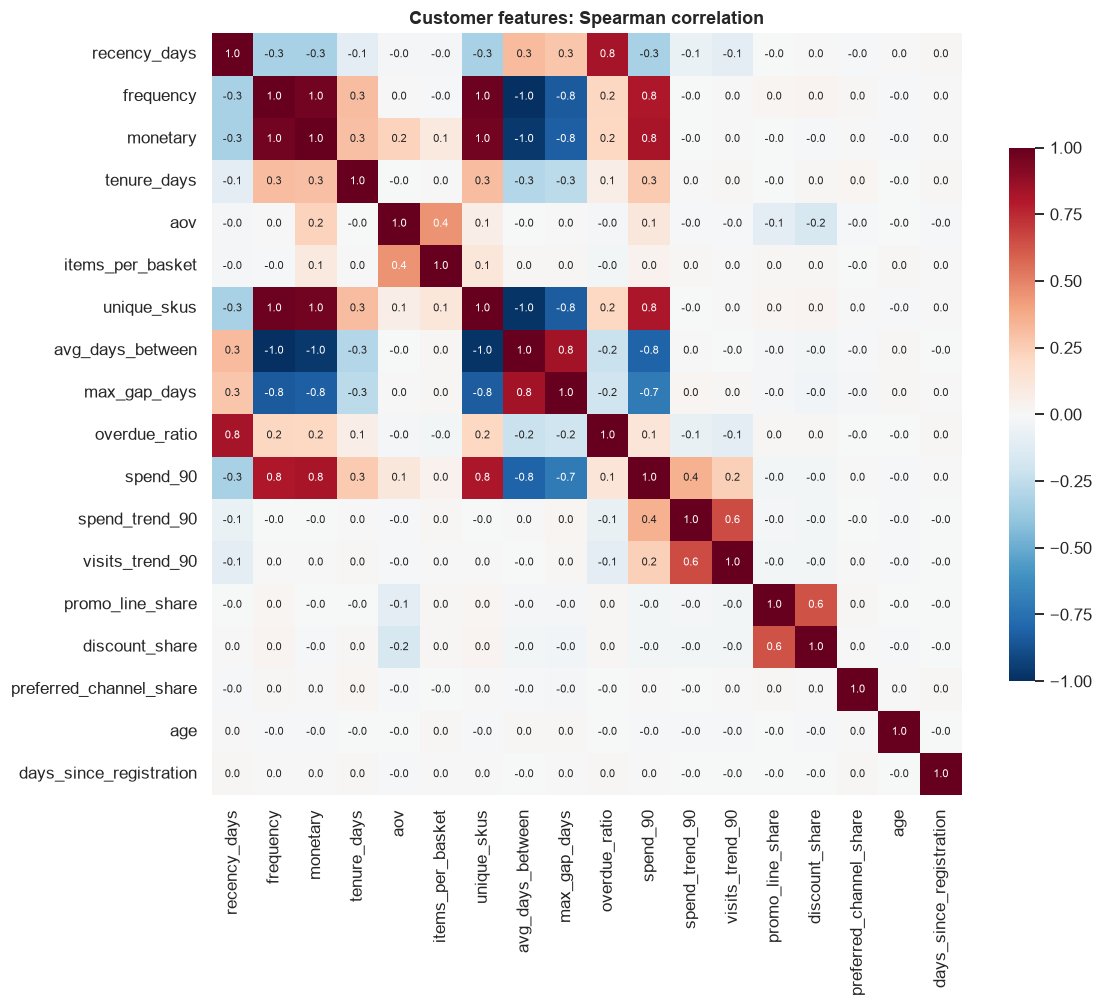

In [7]:
num = ['recency_days', 'frequency', 'monetary', 'tenure_days', 'aov', 'items_per_basket', 'unique_skus',
       'avg_days_between', 'max_gap_days', 'overdue_ratio', 'spend_90', 'spend_trend_90', 'visits_trend_90',
       'promo_line_share', 'discount_share', 'preferred_channel_share', 'age', 'days_since_registration']
plt.figure(figsize=(11, 9))
sns.heatmap(cust[num].corr(method='spearman'), cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            annot=True, fmt='.1f', annot_kws={'size': 7}, cbar_kws={'shrink': .7})
plt.title('Customer features: Spearman correlation'); save('02a_customer_feature_corr'); plt.show()

,frequency,monetary,aov,avg_days_between,recency_days,spend_trend_90,customers
loyalty_segment,,,,,,,
Bronze,326.40,"687,479.54","2,106.23",4.48,3.74,0.36,3969
Silver,466.99,"984,799.30","2,108.70",3.13,2.67,0.31,3106
Gold,700.48,"1,474,600.63","2,105.26",2.09,2.00,0.27,1905
Platinum,"1,072.80","2,261,178.39","2,107.67",1.36,1.52,0.26,1020


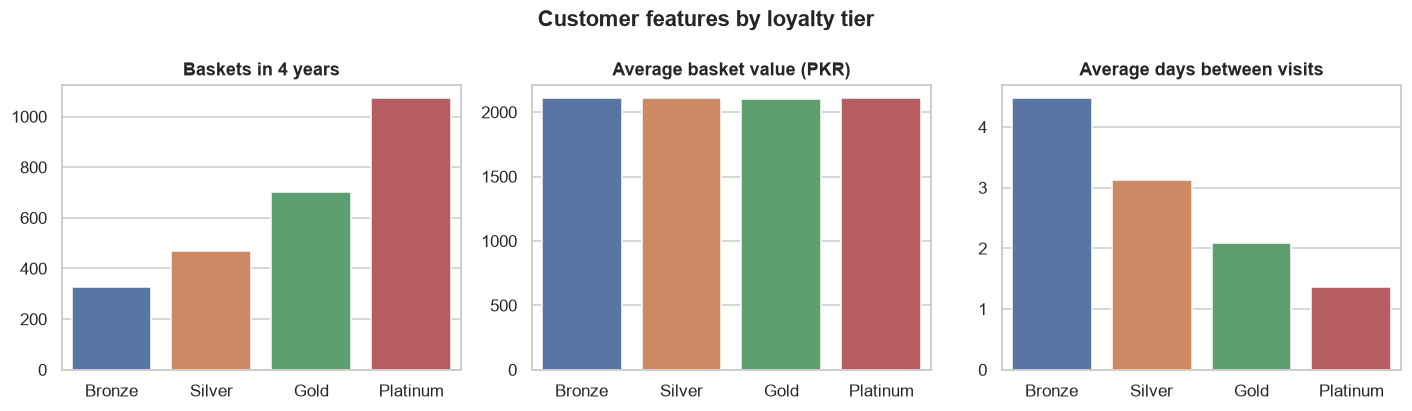

In [8]:
order = ['Bronze', 'Silver', 'Gold', 'Platinum']
prof = cust.groupby('loyalty_segment')[['frequency', 'monetary', 'aov', 'avg_days_between', 'recency_days',
                                         'spend_trend_90']].mean().loc[order]
prof['customers'] = cust['loyalty_segment'].value_counts().loc[order]
display(prof)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, col, title in zip(ax, ['frequency', 'aov', 'avg_days_between'],
                         ['Baskets in 4 years', 'Average basket value (PKR)', 'Average days between visits']):
    sns.barplot(x=prof.index, y=prof[col], ax=a, hue=prof.index, legend=False); a.set_title(title); a.set_xlabel(''); a.set_ylabel('')
plt.suptitle('Customer features by loyalty tier', fontweight='bold'); plt.tight_layout(); save('02b_features_by_loyalty'); plt.show()

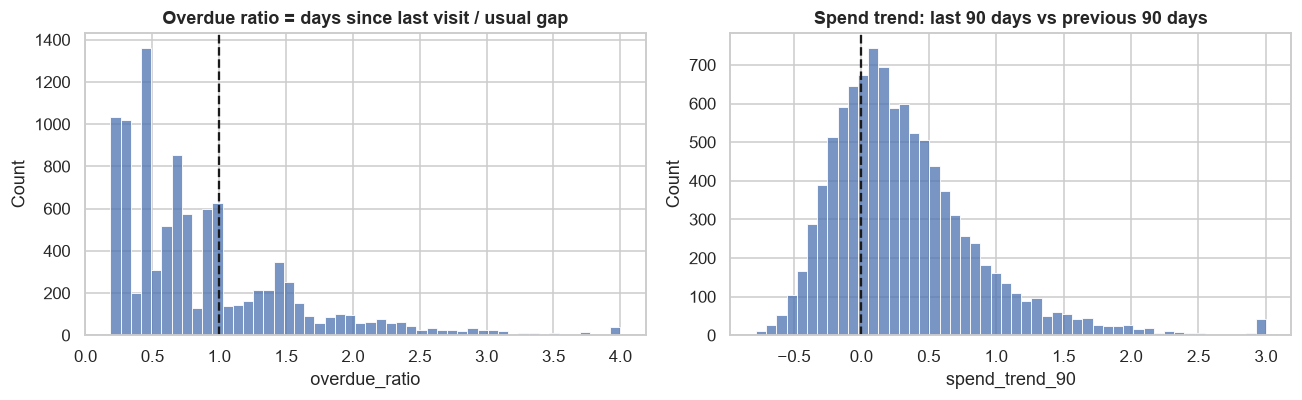

overdue (ratio > 1): 29% of customers | spend fell >30% vs previous 90 days: 8%


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(cust['overdue_ratio'].clip(upper=4), bins=50, ax=ax[0])
ax[0].axvline(1, color='k', ls='--'); ax[0].set_title('Overdue ratio = days since last visit / usual gap')
sns.histplot(cust['spend_trend_90'].clip(-1, 3), bins=50, ax=ax[1])
ax[1].axvline(0, color='k', ls='--'); ax[1].set_title('Spend trend: last 90 days vs previous 90 days')
plt.tight_layout(); save('02c_customer_activity_signals'); plt.show()
print(f"overdue (ratio > 1): {(cust['overdue_ratio'] > 1).mean():.0%} of customers | "
      f"spend fell >30% vs previous 90 days: {(cust['spend_trend_90'] < -0.3).mean():.0%}")

In [10]:
cust.to_csv(PROC / 'customer_features.csv', index_label='customer_id')
print('saved customer_features.csv', cust.shape)

saved customer_features.csv (10000, 48)


**Insights — customer features**
- **Several features carry the same information.** `frequency`, `monetary`, `unique_skus` and `avg_days_between` are almost perfectly correlated (|ρ| ≈ 1.0), because every customer has the same basket size. For K-Means in Step 3, use one of them (e.g. `frequency` or `monetary`), not all four, or that one signal will count several times.
- **Basket value is the same for everyone (~PKR 2,106 in every tier); visit frequency is what differs.** Platinum customers shop every ~1.4 days versus ~4.5 days for Bronze (3.3× more baskets). Loyalty tier is the strongest segmentation signal.
- **Demographics and channel/promo habits are unrelated to spending** (correlations ≈ 0 for age, registration date, promo share, preferred-channel share). They are kept for profiling, but they are unlikely to help the models.
- **Raw 90-day spend trends are mostly seasonal.** The last 90 days (Oct–Dec) include the Nov–Dec peak, so the average customer is +32% versus the previous 90 days. Only 8% of customers fell by more than 30%. This is why the Step 4 churn label compares a quarter with the **same quarter last year**, not with the previous quarter.
- The leakage check passed: features built at 1 July 2025 use only sales before that date, so the same function can safely create churn training data in Step 4.

## 3. Daily sales features (one row per day)
Chain-level daily totals for the forecasting step. Following the EDA, the main target is **units**
(revenue swings with discounts, units reflect demand). Inputs are split into:
- **known in advance** — calendar, trend and the promotion calendar (`store_wide_promo`, `store_wide_discount`, `active_promos`), safe to use for future days;
- **past values** — lags and rolling stats, always shifted by at least one day so a row never contains its own answer;
- **data-hygiene flag** — `stockout_pairs` = number of store × SKU pairs inside a known stockout window that day (lost sales, so low units there are not low demand).

In [11]:
daily = daily_sales(con)
daily_f = add_time_features(daily, target='units')
print(daily_f.shape, '| missing calendar days filled:', int((daily['units'] == 0).sum()))
daily_f.tail(3).T

(1461, 30) | missing calendar days filled: 0


date,2025-12-29,2025-12-30,2025-12-31
revenue,"11,784,706.79","11,765,631.54","11,301,359.70"
units,"18,719.00","18,211.00","18,180.00"
gross_profit,"3,775,825.39","3,773,156.36","3,640,839.02"
receipts,"5,225.00","5,111.00","5,015.00"
lines,"9,916.00","9,755.00","9,680.00"
customers,"3,956.00","3,850.00","3,785.00"
active_promos,0.00,0.00,0.00
store_wide_promo,0.00,0.00,0.00
store_wide_discount,0.00,0.00,0.00
stockout_pairs,228.00,133.00,85.00


In [12]:
# Lag/rolling columns must never use the same day's value
check = daily_f.dropna()
assert (check['units_lag_1'] == daily_f['units'].shift(1).loc[check.index]).all()
assert np.allclose(check['units_roll_mean_7'], daily_f['units'].shift(1).rolling(7).mean().loc[check.index])
lag_cols = [c for c in daily_f.columns if c.startswith('units_')]
corr = daily_f[lag_cols + ['units', 'store_wide_promo', 'store_wide_discount', 'is_nov_dec', 'is_feb', 'trend']] \
         .corr()['units'].drop('units').sort_values(key=abs, ascending=False)
corr.to_frame('correlation with daily units')

,correlation with daily units
units_lag_1,0.97
units_lag_364,0.95
units_roll_mean_7,0.95
units_lag_7,0.88
units_roll_mean_28,0.83
is_nov_dec,0.80
units_lag_14,0.77
trend,0.56
units_lag_28,0.54
is_feb,-0.29


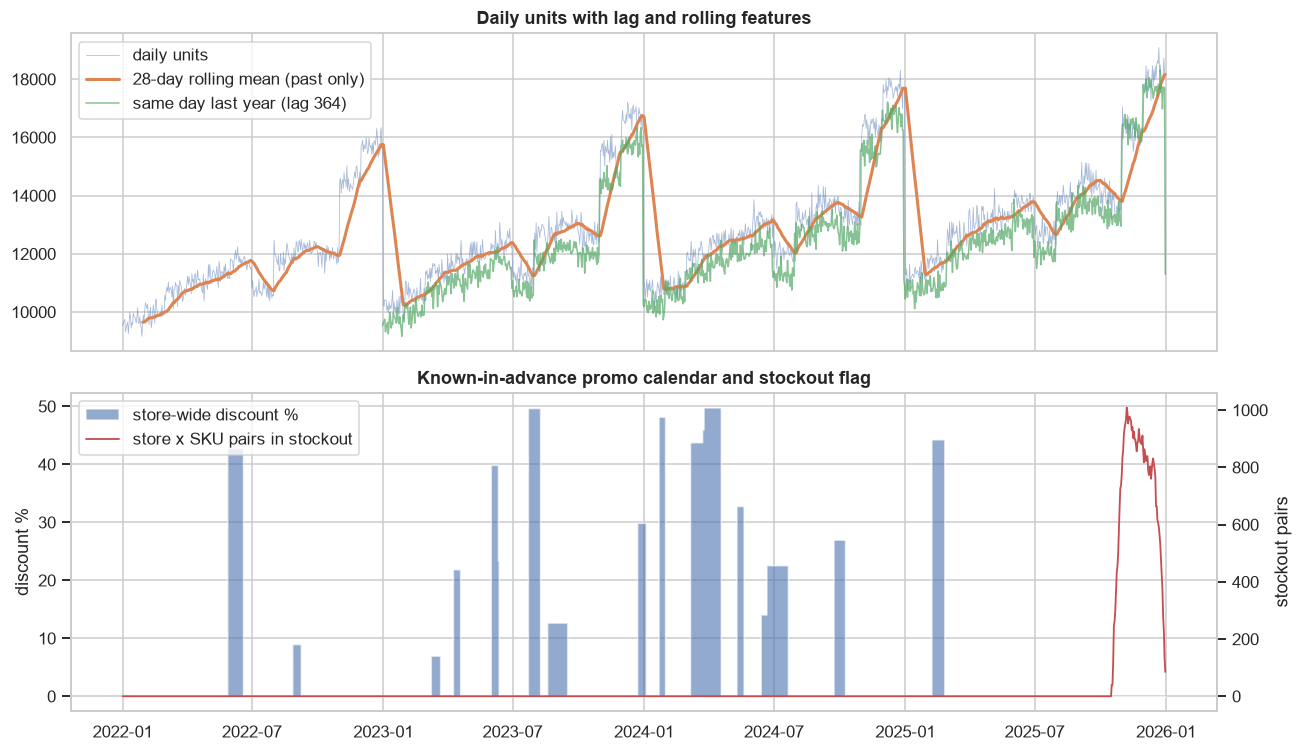

In [13]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(daily_f.index, daily_f['units'], lw=.5, alpha=.5, label='daily units')
ax[0].plot(daily_f.index, daily_f['units_roll_mean_28'], lw=2, label='28-day rolling mean (past only)')
ax[0].plot(daily_f.index, daily_f['units_lag_364'], lw=1, alpha=.7, label='same day last year (lag 364)')
ax[0].legend(loc='upper left'); ax[0].set_title('Daily units with lag and rolling features')
ax[1].fill_between(daily_f.index, daily_f['store_wide_discount'], step='mid', alpha=.6, label='store-wide discount %')
ax2 = ax[1].twinx(); ax2.plot(daily_f.index, daily_f['stockout_pairs'], color='C3', lw=1.2, label='store x SKU pairs in stockout')
ax[1].set_ylabel('discount %'); ax2.set_ylabel('stockout pairs'); ax2.grid(False)
ax[1].set_title('Known-in-advance promo calendar and stockout flag')
h1, l1 = ax[1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax[1].legend(h1 + h2, l1 + l2, loc='upper left')
plt.tight_layout(); save('02d_daily_features'); plt.show()

In [14]:
daily_f.to_csv(PROC / 'daily_sales_features.csv', index_label='date')
print('saved daily_sales_features.csv', daily_f.shape)

saved daily_sales_features.csv (1461, 30)


**Insights — daily features**
- **Past demand predicts the next day very well:** yesterday's units (ρ = 0.97), the same day last year (0.95) and the 7-day average (0.95). The Nov–Dec flag alone has ρ = 0.80, which confirms the strong yearly seasonality seen in the EDA.
- **The seasonality is step-shaped.** Units jump up at the start of November and drop sharply on 1 January, then climb slowly through the year. A 28-day rolling mean reacts late to these steps, so calendar features (`month`, `is_nov_dec`, `is_feb`) and the yearly lag matter more than short rolling averages around the turn of the year.
- `units_lag_364` keeps weekdays aligned, but it shifts by a day each year, so on 31 Dec it points at 1 Jan of the same year (a low day). Expect a small error on the last day of each year; Prophet's yearly seasonality avoids this.
- **Store-wide promotions hardly change units** (ρ ≈ −0.1), matching the EDA (they cut revenue, not demand). They stay in as known-in-advance inputs.
- **Important for Step 5:** the known stockout windows are concentrated in **Oct–Dec 2025** (up to ~1,000 store × SKU pairs out of stock per day). These weeks fall inside the planned test period, so actual units there understate true demand. Report forecast accuracy with this in mind, or also report accuracy on SKUs/stores that were not affected.

## 4. Weekly sales (one row per week)
Weekly totals (Monday–Sunday) are smoother and are what Step 5 reports forecast accuracy on. The partial first and last weeks are dropped.

(208, 7) 2022-01-09 -> 2025-12-28


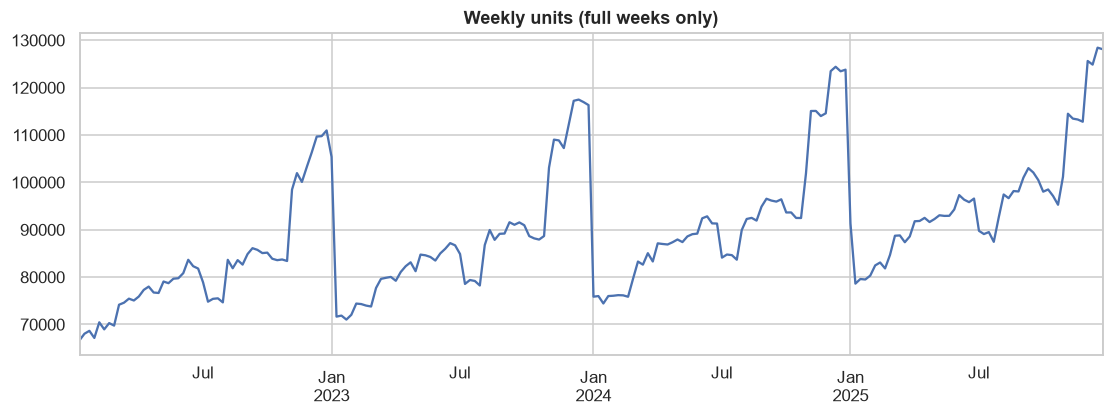

,revenue,units,gross_profit,receipts,lines,store_wide_promo_days,stockout_store_sku_days
date,,,,,,,
2025-11-30,"69,800,265.10","112,801.00","22,460,549.27",32202,60034,0,6267
2025-12-07,"77,670,927.96","125,625.00","25,003,612.72",35583,67035,0,5811
2025-12-14,"77,793,445.76","124,858.00","24,962,054.52",35160,66456,0,5554
2025-12-21,"79,940,538.36","128,433.00","25,679,724.99",35884,68211,0,4926
2025-12-28,"80,491,218.46","128,119.00","25,919,153.23",35672,68117,0,3245


In [15]:
weekly = weekly_sales(daily)
print(weekly.shape, weekly.index.min().date(), '->', weekly.index.max().date())
ax = weekly['units'].plot(figsize=(12, 3.8), title='Weekly units (full weeks only)')
ax.set_xlabel(''); save('02e_weekly_units'); plt.show()
weekly.to_csv(PROC / 'weekly_sales.csv', index_label='week_end')
weekly.tail()

## 5. Product-week demand for the top 20 SKUs
The EDA found extreme product skew, so the top sellers get their own forecasts (the long tail is better handled at category level).
Weeks with no sales are filled with 0, and `stockout_store_days` marks weeks where some stores had no stock (lost sales).

In [16]:
skuw = sku_weekly(con, top_n=20)
share = skuw['revenue'].sum() / con.sql('SELECT SUM(total_value) FROM sales').fetchone()[0]
print(f"{skuw['sku_id'].nunique()} SKUs x {skuw['week_end'].nunique()} weeks = {len(skuw):,} rows | "
      f"top 20 SKUs = {share:.0%} of revenue | zero-sale weeks: {(skuw['units'] == 0).sum()}")
skuw.groupby(['revenue_rank', 'sku_id', 'sku_name', 'category'])[['units', 'revenue', 'stockout_store_days']].sum().head(20)

20 SKUs x 208 weeks = 4,160 rows | top 20 SKUs = 22% of revenue | zero-sale weeks: 0


,,,,units,revenue,stockout_store_days
revenue_rank,sku_id,sku_name,category,,,
1,SKU04321,EliteHome Hair Care Pack of 6,Personal Care,"1,178,141.00","1,062,249,831.71",261.00
2,SKU03727,QuickBite Mobile Accessories 2kg,Electronics & Accessories,"167,073.00","260,348,565.83",208.00
3,SKU04329,SoftTouch Cookware 2kg,Home & Kitchen,"41,176.00","94,261,829.51",493.00
4,SKU04596,ValueChoice Eggs Pack of 6,Dairy & Bakery,"282,682.00","88,579,526.19",180.00
5,SKU01371,PureLife Cookware 1L,Home & Kitchen,"70,354.00","83,754,129.51",360.00
6,SKU03053,PremiumSelect Kids Wear Family Pack,Apparel & Footwear,"21,842.00","83,770,146.56",234.00
7,SKU01189,PureLife Footwear 500g,Apparel & Footwear,"32,511.00","70,026,937.49",108.00
8,SKU04551,DailyBest Cookware Small,Home & Kitchen,"29,722.00","68,904,016.36",306.00
9,SKU04157,PremiumSelect Small Appliances 1L,Electronics & Accessories,"27,334.00","68,807,235.42",312.00


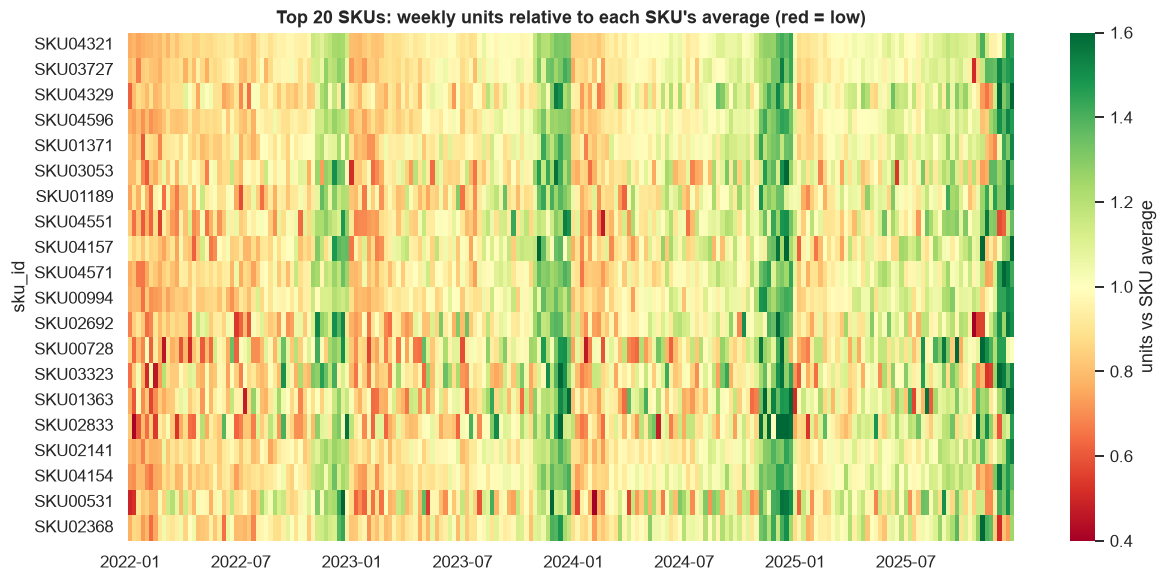

In [17]:
piv = skuw.pivot_table(index='sku_id', columns='week_end', values='units')
piv = piv.loc[skuw.drop_duplicates('sku_id').sort_values('revenue_rank')['sku_id']]
idx = piv.div(piv.mean(axis=1), axis=0)       # each SKU relative to its own average week
fig, ax = plt.subplots(figsize=(13, 6))
sns.heatmap(idx, cmap='RdYlGn', center=1, vmin=.4, vmax=1.6, ax=ax, cbar_kws={'label': 'units vs SKU average'},
            xticklabels=26)
ax.set_xticklabels([pd.Timestamp(t.get_text()).strftime('%Y-%m') for t in ax.get_xticklabels()], rotation=0)
ax.set_title('Top 20 SKUs: weekly units relative to each SKU\'s average (red = low)'); ax.set_xlabel('')
save('02f_sku_weekly_heatmap'); plt.show()

In [18]:
skuw.to_csv(PROC / 'sku_weekly.csv', index=False)
print('saved sku_weekly.csv', skuw.shape)

saved sku_weekly.csv (4160, 19)


**Insights — top-20 SKU weekly demand**
- The top 20 SKUs make up **22% of revenue**, and every one of them sells every week (no zero weeks), so each can be forecast individually. The single biggest SKU (`SKU04321`) alone sells ~1.2M units.
- **All top SKUs share the chain's yearly pattern** (green in Nov–Dec, red in Jan–Feb). A global model with SKU attributes, or one Prophet model per SKU with shared seasonality settings, both make sense.
- Smaller SKUs in the list are noisier week to week (more red/green speckle), so their forecasts will have wider uncertainty and need larger safety stock in Step 6.
- Every one of the top 20 SKUs has stockout days in late 2025 (`stockout_store_days` > 0). This column lets Step 5 down-weight or exclude those weeks, and lets Step 6 measure the lost sales.

## 6. Inventory features (one row per store × SKU in the snapshot)
Stock position (vs reorder point and safety stock), how fast the item sells in that store, and how long since it was restocked or sold.
The `label_*` columns come from the answer key `sku_inventory_flags.csv`; they are kept **only to evaluate** the Step 6 rules, never as model inputs.

In [19]:
inv = inventory_features(con, SNAPSHOT)
print(f'{len(inv):,} store x SKU rows')
inv['group'] = np.select([inv['label_stockout_risk'] == 1, inv['label_slow_mover'] == 1],
                         ['stockout risk', 'slow mover'], 'not flagged')
cols = ['stock_on_hand', 'stock_to_reorder_point', 'out_of_stock', 'below_reorder_point', 'avg_daily_units_365',
        'velocity_ratio_28_365', 'days_since_restock', 'days_since_last_sale', 'sudden_zero_sales', 'stock_value']
summary = inv.groupby('group')[cols].median().T
summary.loc['rows'] = inv['group'].value_counts()
summary.loc['share out_of_stock'] = inv.groupby('group')['out_of_stock'].mean()
summary.loc['share sudden_zero_sales'] = inv.groupby('group')['sudden_zero_sales'].mean()
summary[['stockout risk', 'slow mover', 'not flagged']]

21,228 store x SKU rows


group,stockout risk,slow mover,not flagged
stock_on_hand,0.00,259.00,76.00
stock_to_reorder_point,0.00,4.48,1.52
out_of_stock,1.00,0.00,0.00
below_reorder_point,1.00,0.00,0.00
avg_daily_units_365,0.41,0.03,0.05
velocity_ratio_28_365,1.11,0.00,0.95
days_since_restock,115.00,181.00,31.00
days_since_last_sale,3.00,32.00,17.00
sudden_zero_sales,0.00,0.00,0.00
stock_value,0.00,"54,842.71","15,560.24"


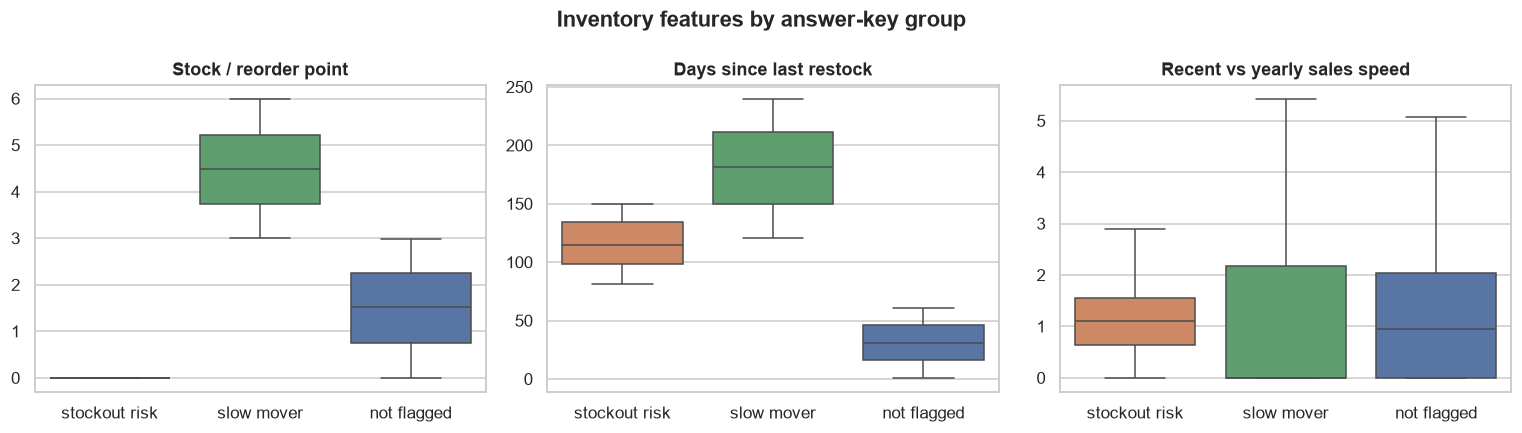

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
order = ['stockout risk', 'slow mover', 'not flagged']
for a, col, title in zip(ax, ['stock_to_reorder_point', 'days_since_restock', 'velocity_ratio_28_365'],
                         ['Stock / reorder point', 'Days since last restock', 'Recent vs yearly sales speed']):
    sns.boxplot(data=inv, x='group', y=col, order=order, ax=a, showfliers=False, hue='group', legend=False)
    a.set_title(title); a.set_xlabel(''); a.set_ylabel('')
plt.suptitle('Inventory features by answer-key group', fontweight='bold'); plt.tight_layout()
save('02g_inventory_features'); plt.show()

In [21]:
inv.drop(columns='group').to_csv(PROC / 'inventory_features.csv', index=False)
print('saved inventory_features.csv', inv.shape)

saved inventory_features.csv (21228, 28)


**Insights — inventory features**
- **The answer key is easy to spot from the snapshot alone.** Every *stockout-risk* row has `stock_on_hand = 0` (only ~1% of unflagged rows do). *Slow movers* sit at 3–6× their reorder point with no restock for 120+ days, while unflagged rows are at most 3× and were restocked within ~60 days. Simple stock-ratio rules in Step 6 should therefore score very high against the answer key.
- **Sales velocity alone separates the groups much less.** Slow movers sell less (median 0.03 vs 0.05 units/day per store), and their recent-vs-yearly speed overlaps heavily with normal items. A rule that only looks at sales history would be a harder and more realistic test.
- **Data quirk:** the stockout-risk rows show zero stock, yet most of them still have sales in the last few days (median 3 days since the last sale), because the stockout windows ended before the snapshot date. As a result, `sudden_zero_sales` catches only 1% of them. In Step 6, treat the snapshot stock level and the sales history as two separate signals.
- Overstock is where the money is: a median slow-mover row holds ~PKR 55k of stock at cost, versus ~PKR 16k for an unflagged row.

## 7. Summary of outputs

In [22]:
files = ['sales_clean.parquet', 'customer_features.csv', 'daily_sales_features.csv', 'weekly_sales.csv',
         'sku_weekly.csv', 'inventory_features.csv']
rows = []
for f in files:
    p = PROC / f
    shape = con.sql(f"SELECT COUNT(*) FROM read_parquet('{p.as_posix()}')").fetchone()[0] if p.suffix == '.parquet' \
            else len(pd.read_csv(p, usecols=[0]))
    rows.append({'file': f, 'rows': f'{shape:,}', 'size_MB': round(p.stat().st_size / 1e6, 1)})
pd.DataFrame(rows)

,file,rows,size_MB
0,sales_clean.parquet,"9,959,019",152.80
1,customer_features.csv,"10,000",6.80
2,daily_sales_features.csv,"1,461",0.30
3,weekly_sales.csv,208,0.00
4,sku_weekly.csv,"4,160",0.70
5,inventory_features.csv,"21,228",4.30


**Done-when check (Step 2)**
- ✅ `customer_features.csv` — 10,000 customers × 48 features, built by a snapshot-based function (leak-free for Step 4)
- ✅ `daily_sales_features.csv` and `weekly_sales.csv` — continuous calendar, shifted lags/rolls, promo calendar, stockout flag
- ✅ `sku_weekly.csv` — top-20 SKUs × 208 weeks, zero-filled, with stockout days
- ✅ `inventory_features.csv` — 21,228 store × SKU rows with stock ratios, velocity and the answer-key labels (evaluation only)
- ✅ Correlation heatmap of customer features saved (`reports/figures/02a_customer_feature_corr.png`)

`sales_clean.parquet` is not committed to git (too large); re-running this notebook rebuilds it in seconds from the raw CSV.

**Carry forward to the next steps**
1. **Segmentation (Step 3):** use `recency_days`, one of `frequency`/`monetary`, `aov`, `spend_trend_90` and `overdue_ratio`; log-transform and scale them; profile the clusters against `loyalty_segment`.
2. **Churn (Step 4):** nobody stops buying, so define churn as *next-quarter spend down >30% versus the same quarter last year*. Build X with `customer_features(con, cutoff)` and the label from sales after the cutoff.
3. **Forecasting (Step 5):** target = units; the test weeks (Nov–Dec 2025) contain injected stockouts, so flag them when reporting accuracy.
4. **Inventory (Step 6):** score rules against the `label_*` columns, and compare stock-based rules with sales-only rules.